In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Not sure of your dataset's folder name? Run this line first:
# !find /kaggle/input -name "*.csv"

df_raw = pd.read_csv("/kaggle/input/datasets/mugishaleonce/country/Country Schools.csv")
df = df_raw.copy()   # keep the original untouched, same as the guide does
print(df.shape)
df.head()

(50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [2]:
df.info()
df.describe().T
df.isna().sum()
df.tail(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     object 
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     object 
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 3.3+ KB


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


In [3]:
df_clean = df_raw.copy()
df_clean = df_clean.dropna(how="all", subset=df_clean.columns.drop("FID"))
print(df_clean.shape)

(48, 8)


In [4]:
df_clean = df_clean[df_clean["SNO"].str.strip().str.upper() != "TOTAL"].copy()
print(df_clean.shape)

(47, 8)


In [5]:
df_clean = df_clean.rename(columns={"SNO": "County"})
df_clean["County"] = df_clean["County"].str.strip().str.title()
df_clean.head()

,County,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,Turkana,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,Homa Bay,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,West Pokot,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,Kitui,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,Tana River,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [6]:
df_clean["PercentageInstalled"] = df_clean["PercentageInstalled"].str.rstrip("%").astype(float)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47 entries, 0 to 46
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   County                 47 non-null     object 
 1   TOTALSCHOOLS           47 non-null     float64
 2   TotalSchoolsInstalled  47 non-null     float64
 3   SchoolsPending         47 non-null     float64
 4   PercentageInstalled    47 non-null     float64
 5   InstalledLDDs          47 non-null     float64
 6   InstalledTDDs          47 non-null     float64
 7   FID                    47 non-null     int64  
dtypes: float64(6), int64(1), object(1)
memory usage: 3.3+ KB


In [7]:
print("Duplicates:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

Duplicates: 0


In [8]:
print("Installed + Pending == Total ?",
      (df_clean.TotalSchoolsInstalled + df_clean.SchoolsPending == df_clean.TOTALSCHOOLS).all())
print("InstalledTDDs == 2 x TotalSchoolsInstalled ?",
      (df_clean.InstalledTDDs == 2 * df_clean.TotalSchoolsInstalled).all())

Installed + Pending == Total ? True
InstalledTDDs == 2 x TotalSchoolsInstalled ? True


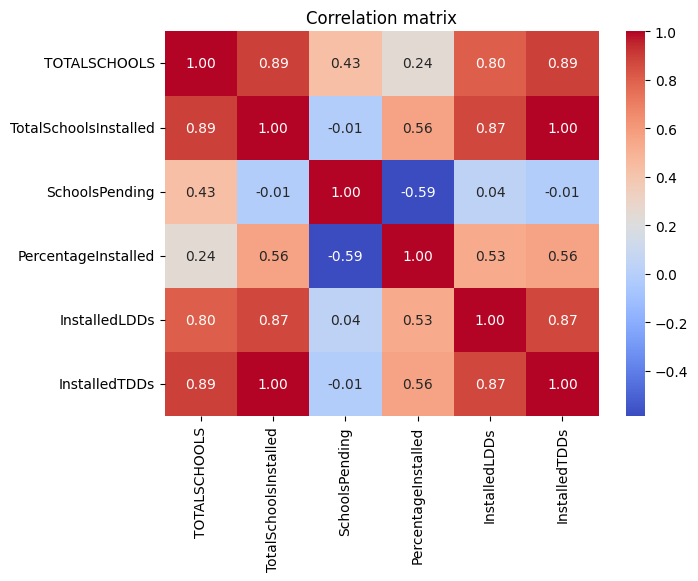

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_clean.drop(columns=["County", "FID"]).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler

features = ["TOTALSCHOOLS", "TotalSchoolsInstalled", "PercentageInstalled", "InstalledLDDs"]
X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

print(X_scaled.mean(axis=0).round(2))
print(X_scaled.std(axis=0).round(2))

[-0.  0.  0.  0.]
[1. 1. 1. 1.]


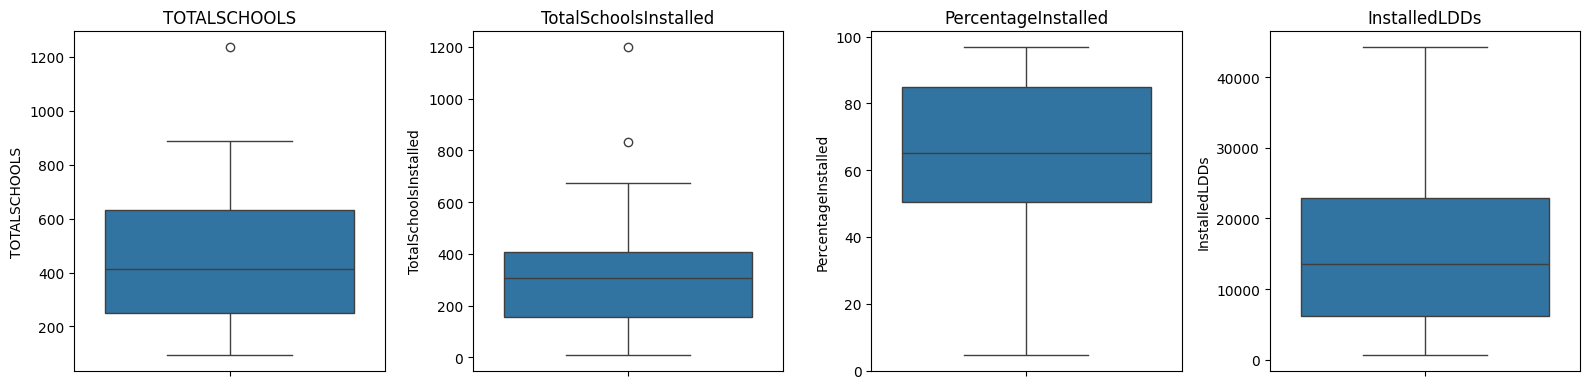

In [11]:
fig, axes = plt.subplots(1, len(features), figsize=(16, 4))
for ax, c in zip(axes, features):
    sns.boxplot(y=df_clean[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [12]:
for c in features:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df_clean[c] < q1 - 1.5*iqr) | (df_clean[c] > q3 + 1.5*iqr)
    print(f"{c:24s}", list(df_clean.County[mask]))

TOTALSCHOOLS             ['Kitui']
TotalSchoolsInstalled    ['Kitui', 'Makueni']
PercentageInstalled      []
InstalledLDDs            []


In [13]:
z = pd.DataFrame(X_scaled, columns=features)
for c in features:
    print(f"{c:24s}", [(df_clean.County[i], round(z[c][i], 2)) for i in z.index[z[c].abs() > 3]])

TOTALSCHOOLS             [('Kitui', np.float64(3.08))]
TotalSchoolsInstalled    [('Kitui', np.float64(3.92))]
PercentageInstalled      []
InstalledLDDs            []


In [14]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.1, random_state=42)
df_clean["iso_flag"] = iso.fit_predict(X_scaled)           # -1 = anomaly, 1 = normal
df_clean["iso_score"] = iso.decision_function(X_scaled)    # lower = more anomalous

print("Isolation Forest:", list(df_clean.County[df_clean.iso_flag == -1]))
df_clean.sort_values("iso_score").head(8)[["County"] + features + ["iso_score"]]

Isolation Forest: ['Turkana', 'Kitui', 'Makueni', 'Kakamega', 'Marsabit']


,County,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled,InstalledLDDs,iso_score
3,Kitui,1238.0,1200.0,96.93,42162.0,-0.175940
13,Makueni,887.0,833.0,93.91,30973.0,-0.030010
17,Kakamega,880.0,572.0,65.00,44338.0,-0.022934
38,Marsabit,138.0,8.0,5.80,606.0,-0.011864
0,Turkana,358.0,37.0,10.34,3744.0,-0.006253
30,Mandera,198.0,9.0,4.55,1046.0,0.004169
36,Wajir,211.0,11.0,5.21,855.0,0.014637
14,Lamu,93.0,89.0,95.70,3083.0,0.023547


In [15]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=5, contamination=0.1)
df_clean["lof_flag"] = lof.fit_predict(X_scaled)

print("LOF:", list(df_clean.County[df_clean.lof_flag == -1]))
both = df_clean[(df_clean.iso_flag == -1) & (df_clean.lof_flag == -1)].County.tolist()
print("Flagged by BOTH:", both)

LOF: ['Homa Bay', 'Kitui', 'Makueni', 'Kakamega', 'Bungoma']
Flagged by BOTH: ['Kitui', 'Makueni', 'Kakamega']


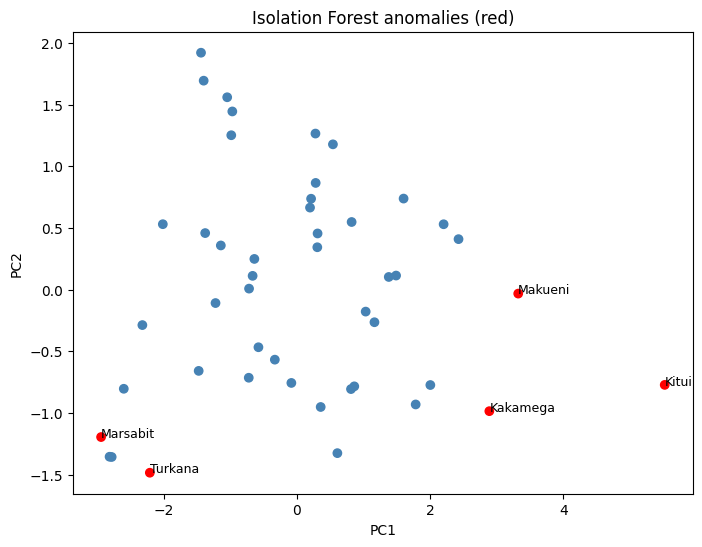

In [16]:
from sklearn.decomposition import PCA

P = PCA(2).fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
plt.scatter(P[:, 0], P[:, 1], c=np.where(df_clean.iso_flag == -1, "red", "steelblue"))
for i, n in enumerate(df_clean.County):
    if df_clean.iso_flag[i] == -1:
        plt.annotate(n, P[i], fontsize=9)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Isolation Forest anomalies (red)")
plt.show()

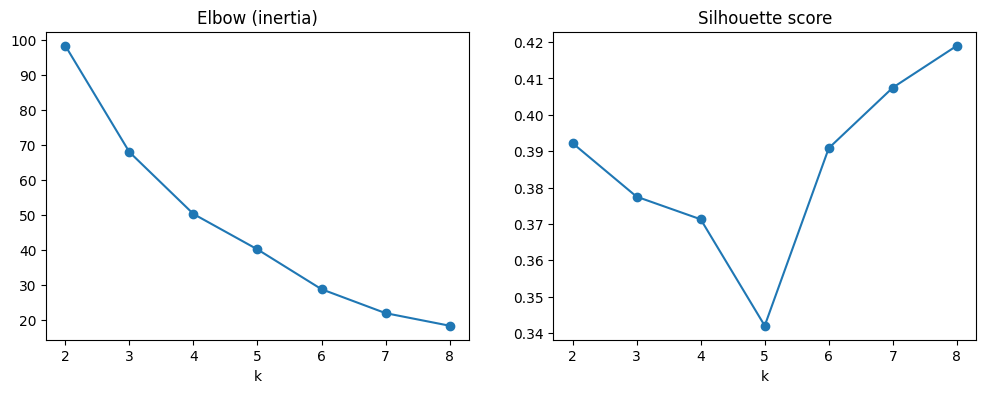

,k,inertia,silhouette
0,2,98.4,0.392
1,3,68.1,0.377
2,4,50.4,0.371
3,5,40.3,0.342
4,6,28.9,0.391
5,7,22.0,0.407
6,8,18.5,0.419


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-");     ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.show()

pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)})

In [18]:
km = KMeans(3, n_init=10, random_state=42).fit(X_scaled)
df_clean["cluster"] = km.labels_
print("Silhouette:", round(silhouette_score(X_scaled, km.labels_), 3))

profile = df_clean.groupby("cluster")[features].mean().round(1)
profile["n_counties"] = df_clean["cluster"].value_counts().sort_index()
display(profile)

for c, g in df_clean.groupby("cluster"):
    print(f"Cluster {c}: {list(g.County)}\n")

Silhouette: 0.377


,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled,InstalledLDDs,n_counties
cluster,,,,,
0,339.5,230.8,71.5,10542.7,23
1,724.4,531.1,73.1,27443.1,17
2,229.4,41.7,16.6,2086.0,7


Cluster 0: ['West Pokot', 'Tana River', 'Taita Taveta', 'Uasin Gishu', 'Vihiga', 'Nyamira', 'Mombasa', 'Lamu', 'Elgeyo', 'Trans Nzoia', 'Kwale', 'Kericho', 'Laikipia', 'Kirinyaga', 'Isiolo', 'Kiambu', "Murang'A", 'Nyandarua', 'Nairobi', 'Tharaka Nithi', 'Baringo', 'Kajiado', 'Embu']

Cluster 1: ['Homa Bay', 'Kitui', 'Migori', 'Narok', 'Nandi', 'Makueni', 'Kisii', 'Kisumu', 'Kakamega', 'Bungoma', 'Bomet', 'Kilifi', 'Busia', 'Siaya', 'Meru', 'Machakos', 'Nakuru']

Cluster 2: ['Turkana', 'Garissa', 'Mandera', 'Nyeri', 'Wajir', 'Marsabit', 'Samburu']



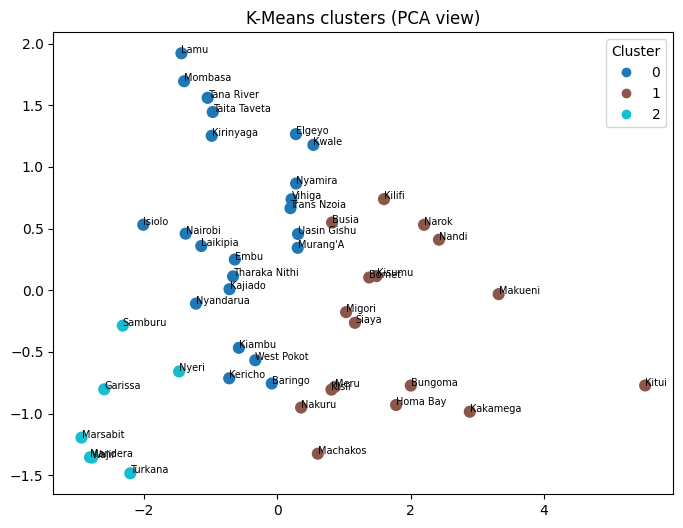

In [19]:
P = PCA(2).fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
sc = plt.scatter(P[:, 0], P[:, 1], c=df_clean["cluster"], cmap="tab10", s=60)
for i, n in enumerate(df_clean.County):
    plt.annotate(n, P[i], fontsize=7)
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("K-Means clusters (PCA view)")
plt.show()

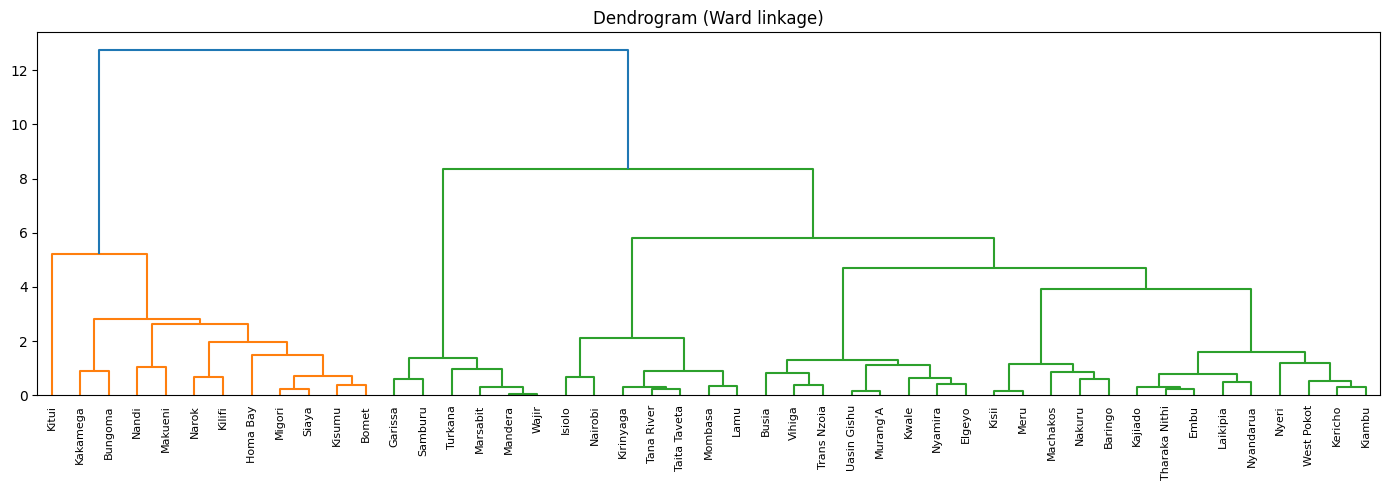

hier_cluster   0   1  2
cluster                
0             23   0  0
1              5  12  0
2              1   0  6


In [20]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Z, labels=df_clean.County.values, leaf_rotation=90)
plt.title("Dendrogram (Ward linkage)")
plt.tight_layout()
plt.show()

df_clean["hier_cluster"] = AgglomerativeClustering(3, linkage="ward").fit_predict(X_scaled)
print(pd.crosstab(df_clean.cluster, df_clean.hier_cluster))

In [21]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=1.0, min_samples=3).fit(X_scaled)
df_clean["dbscan"] = db.labels_
print(df_clean["dbscan"].value_counts().sort_index())
print("Noise points:", list(df_clean.County[df_clean.dbscan == -1]))

dbscan
-1     4
 0    43
Name: count, dtype: int64
Noise points: ['Kitui', 'Makueni', 'Kakamega', 'Bungoma']


In [22]:
summary = df_clean[["County"] + features].copy()
summary["IQR/Z"]  = summary.County.isin(["Kitui", "Makueni"])
summary["IsoForest"] = df_clean.iso_flag == -1
summary["LOF"]       = df_clean.lof_flag == -1
summary["DBSCAN"]    = df_clean.dbscan == -1
summary["n_methods"] = summary[["IQR/Z", "IsoForest", "LOF", "DBSCAN"]].sum(axis=1)
summary[summary.n_methods > 0].sort_values("n_methods", ascending=False)

,County,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled,InstalledLDDs,IQR/Z,IsoForest,LOF,DBSCAN,n_methods
3,Kitui,1238.0,1200.0,96.93,42162.0,True,True,True,True,4
13,Makueni,887.0,833.0,93.91,30973.0,True,True,True,True,4
17,Kakamega,880.0,572.0,65.00,44338.0,False,True,True,True,3
18,Bungoma,741.0,456.0,61.54,38744.0,False,False,True,True,2
0,Turkana,358.0,37.0,10.34,3744.0,False,True,False,False,1
1,Homa Bay,875.0,552.0,63.09,22982.0,False,False,True,False,1
38,Marsabit,138.0,8.0,5.80,606.0,False,True,False,False,1


In [23]:
print("Raw shape:", df_raw.shape, "-> Clean shape:", df_clean.shape)
print("Features used:", features)
print(df_clean["cluster"].value_counts().sort_index())

Raw shape: (50, 8) -> Clean shape: (47, 14)
Features used: ['TOTALSCHOOLS', 'TotalSchoolsInstalled', 'PercentageInstalled', 'InstalledLDDs']
cluster
0    23
1    17
2     7
Name: count, dtype: int64
